# Taller 4

**Asignatura:** Aprendizaje Computacional  
**Programa:** Ingeniería de Sistemas  
**GRUPO:** Robin Alexander Montoya, Tomas Correa y Samuel Arango

## Dataset
link: https://www.kaggle.com/datasets/arpitsharmaml/student-academic-risk-prediction-dataset/data#1

Se utiliza el archivo **student_data_100000.csv**, ubicado en `archive (2)`. Contiene información sobre asistencia, horas de estudio, desempeño académico y contexto del estudiante.

**Objetivo:** clasificar el nivel de riesgo académico (`risk_category`) en tres categorías: `Safe`, `At-Risk` o `High-Risk`.

## 1.2 Preprocesamiento

Carga del dataset, verificación de valores faltantes y nulos, limpieza y definición de los pipelines de preprocesamiento e imputación.

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Carga de datos
DATA_PATH = Path("archive (2)") / "student_data_100000.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró el dataset: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
TARGET = "risk_category"
if TARGET not in df.columns:
    raise ValueError(f"No se encontró la columna objetivo '{TARGET}' en el dataset.")

# Verificación de calidad de datos
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
print(f"Valores faltantes: {df.isna().sum().sum()}")
print(f"Filas duplicadas: {df.duplicated().sum()}")

# Definición de transformadores y pipelines de preprocesamiento
feature_columns = df.drop(columns=[TARGET]).columns
numeric_features = df[feature_columns].select_dtypes(include="number").columns.tolist()
categorical_features = df[feature_columns].select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            numeric_features,
        ),
        (
            "categorical",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            categorical_features,
        )
    ],
    remainder="drop",
)
print("Preprocesamiento configurado correctamente.")

Filas: 100,000 | Columnas: 11
Valores faltantes: 2000
Filas duplicadas: 0
Preprocesamiento configurado correctamente.


## 1.3 Definir X e Y, describir columnas y .head()

Se separan las variables características ($X$) de la variable objetivo ($Y$). Se muestra la descripción de los datos y las primeras filas del dataset.

In [2]:
# Definición de X e Y
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

# Descripción de columnas y tipos de datos
print("\n--- Tipos de datos y no nulos ---")
display(pd.DataFrame({"tipo": X.dtypes.astype(str), "no_nulos": X.notna().sum()}))

# Estadísticas descriptivas de las columnas
print("\n--- Estadísticas descriptivas ---")
display(X.describe().T)

# Primeras filas (.head())
print("\n--- Primeras 5 filas (.head()) ---")
display(df.head())

X shape: (100000, 10)
y shape: (100000,)

--- Tipos de datos y no nulos ---


,tipo,no_nulos
attendance,float64,99000
study_hours,float64,99000
past_failures,int64,100000
assignments_completed_pct,float64,100000
parental_education,object,100000
family_income,object,100000
extracurricular,object,100000
internet_access,object,100000
previous_grade,float64,100000
final_score,float64,100000



--- Estadísticas descriptivas ---


,count,mean,std,min,25%,50%,75%,max
attendance,99000.0,72.972567,21.562735,10.0,58.15,75.065,91.94,100.0
study_hours,99000.0,6.101901,3.722512,0.0,3.30,6.000,8.70,15.0
past_failures,100000.0,1.848650,1.491297,0.0,1.00,2.000,3.00,5.0
assignments_completed_pct,100000.0,72.929616,21.656246,0.0,58.09,75.070,91.83,100.0
previous_grade,100000.0,72.967067,21.624269,0.0,58.19,75.040,91.89,100.0
final_score,100000.0,62.968236,15.888285,0.0,52.22,63.160,73.99,100.0



--- Primeras 5 filas (.head()) ---


,attendance,study_hours,past_failures,assignments_completed_pct,parental_education,family_income,extracurricular,internet_access,previous_grade,final_score,risk_category
0,87.42,10.12,2,100.00,Secondary,Low,Yes,Yes,46.80,76.08,Safe
1,71.54,1.38,3,36.70,Secondary,High,Yes,Yes,48.05,43.21,High-Risk
2,91.19,8.30,5,64.38,Secondary,Low,No,Yes,69.40,60.89,At-Risk
3,100.00,3.52,4,93.77,Secondary,Low,No,No,58.07,45.47,At-Risk
4,69.15,4.69,1,72.36,Primary,Low,Yes,Yes,50.55,37.15,High-Risk


## 1.4 Train/test split

Se realiza la división estratificada del conjunto de datos en entrenamiento (80%) y prueba (20%), conservando la proporción de las tres categorías de riesgo.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Entrenamiento (Train): {X_train.shape[0]} filas")
print(f"Prueba (Test): {X_test.shape[0]} filas")

print("\nDistribución de clases en Entrenamiento:")
print(y_train.value_counts())

print("\nDistribución de clases en Prueba:")
print(y_test.value_counts())

Entrenamiento (Train): 80000 filas
Prueba (Test): 20000 filas

Distribución de clases en Entrenamiento:
risk_category
At-Risk      39992
Safe         20009
High-Risk    19999
Name: count, dtype: int64

Distribución de clases en Prueba:
risk_category
At-Risk      9998
Safe         5002
High-Risk    5000
Name: count, dtype: int64


## 1.5 Crear y entrenar el KNN

Usamos el `preprocessor` de la sección 1.2 dentro de un `Pipeline` junto con el KNN, así la imputación, el escalado y el one-hot se ajustan solo con los datos de entrenamiento. Se escalan las variables numéricas porque KNN trabaja con distancias y si no, las columnas con números más grandes pesan más.

Para escoger el número de vecinos (k) probamos varios valores. Para no usar el test en esa decisión, separamos una parte del train como validación y comparamos el accuracy ahí. Después entrenamos el modelo final con todo el train y el mejor k.

In [4]:
from sklearn.neighbors import KNeighborsClassifier

# parte del train se usa como validación (el test no se toca)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# probar varios valores de k
resultados_k = {}
for k in [3, 5, 11, 21, 31]:
    modelo_k = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k, n_jobs=-1)),
    ])
    modelo_k.fit(X_tr, y_tr)
    resultados_k[k] = round(modelo_k.score(X_val, y_val), 4)
    print("k =", k, "-> accuracy en validación:", resultados_k[k])

mejor_k = max(resultados_k, key=resultados_k.get)
print("\nMejor k:", mejor_k)

# modelo final con todo el train y el mejor k
knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=mejor_k, n_jobs=-1)),
])
knn_model.fit(X_train, y_train)
print("Modelo entrenado con k =", knn_model.named_steps["classifier"].n_neighbors)

k = 3 -> accuracy en validación: 0.8501
k = 5 -> accuracy en validación: 0.8642
k = 11 -> accuracy en validación: 0.8704
k = 21 -> accuracy en validación: 0.8729
k = 31 -> accuracy en validación: 0.8726

Mejor k: 21
Modelo entrenado con k = 21


## 1.6 Predicciones

Se hacen las predicciones sobre train y sobre test. Con tantos datos la de train se demora un poco.

In [5]:
y_train_pred = knn_model.predict(X_train)
y_test_pred = knn_model.predict(X_test)

print("Predicciones en train:", len(y_train_pred))
print("Predicciones en test:", len(y_test_pred))

# primeras 10 filas de test: real vs predicho
comparacion = pd.DataFrame({"real": y_test.values[:10], "predicho": y_test_pred[:10]})
display(comparacion)

Predicciones en train: 80000
Predicciones en test: 20000


,real,predicho
0,High-Risk,High-Risk
1,At-Risk,At-Risk
2,At-Risk,At-Risk
3,High-Risk,High-Risk
4,At-Risk,At-Risk
5,At-Risk,At-Risk
6,At-Risk,At-Risk
7,At-Risk,At-Risk
8,At-Risk,At-Risk
9,High-Risk,High-Risk


## 1.7 Evaluación

Se calcula el accuracy y la matriz de confusión en train y en test.

Accuracy train: 0.8948
Accuracy test: 0.8854

Matriz de confusión train (filas = real, columnas = predicho):


,At-Risk,High-Risk,Safe
At-Risk,37617,871,1504
High-Risk,3433,16562,4
Safe,2600,3,17406



Matriz de confusión test (filas = real, columnas = predicho):


,At-Risk,High-Risk,Safe
At-Risk,9328,262,408
High-Risk,921,4078,1
Safe,698,2,4302


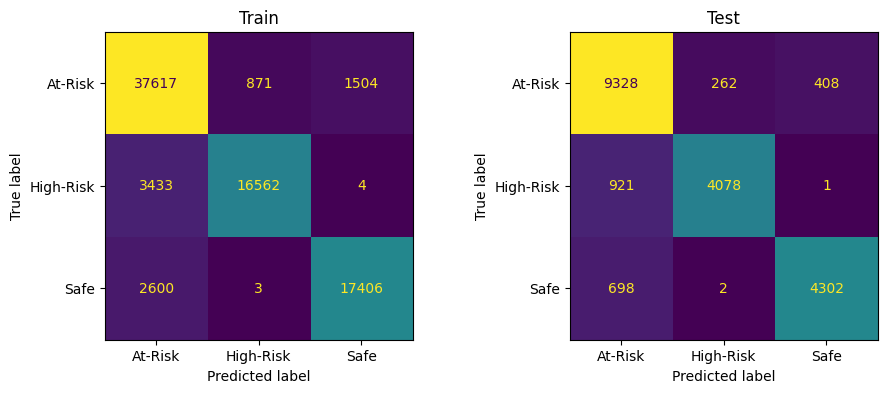

Reporte de clasificación train:
              precision    recall  f1-score   support

     At-Risk       0.86      0.94      0.90     39992
   High-Risk       0.95      0.83      0.88     19999
        Safe       0.92      0.87      0.89     20009

    accuracy                           0.89     80000
   macro avg       0.91      0.88      0.89     80000
weighted avg       0.90      0.89      0.89     80000

Reporte de clasificación test:
              precision    recall  f1-score   support

     At-Risk       0.85      0.93      0.89      9998
   High-Risk       0.94      0.82      0.87      5000
        Safe       0.91      0.86      0.89      5002

    accuracy                           0.89     20000
   macro avg       0.90      0.87      0.88     20000
weighted avg       0.89      0.89      0.89     20000



In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print("Accuracy train:", round(accuracy_score(y_train, y_train_pred), 4))
print("Accuracy test:", round(accuracy_score(y_test, y_test_pred), 4))

clases = knn_model.named_steps["classifier"].classes_
cm_train = confusion_matrix(y_train, y_train_pred, labels=clases)
cm_test = confusion_matrix(y_test, y_test_pred, labels=clases)

print("\nMatriz de confusión train (filas = real, columnas = predicho):")
display(pd.DataFrame(cm_train, index=clases, columns=clases))
print("\nMatriz de confusión test (filas = real, columnas = predicho):")
display(pd.DataFrame(cm_test, index=clases, columns=clases))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm_train, display_labels=clases).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Train")
ConfusionMatrixDisplay(cm_test, display_labels=clases).plot(ax=ax[1], colorbar=False)
ax[1].set_title("Test")
plt.show()

print("Reporte de clasificación train:")
print(classification_report(y_train, y_train_pred))
print("Reporte de clasificación test:")
print(classification_report(y_test, y_test_pred))

Con los valores de k que probamos, el accuracy en validación fue subiendo hasta k = 21 (0.8729) y después se estancó (0.8726 con k = 31), así que usamos k = 21. Con k = 5 daba 0.8642, o sea que subir el número de vecinos sí ayudó un poco.

El modelo final sacó 0.8948 en train y 0.8854 en test. La clase más grande (At-Risk) es la mitad de los datos, así que un modelo que siempre dijera At-Risk sacaría 0.5 y el KNN está aprendiendo bastante mejor que eso. La diferencia entre train y test es de solo un punto, por lo que no parece haber sobreajuste.

En la matriz de test casi todos los errores involucran a At-Risk: 921 estudiantes High-Risk y 698 Safe quedaron como At-Risk, y a la inversa 262 y 408 At-Risk se fueron a High-Risk y Safe. Entre Safe y High-Risk casi no hay errores (3 casos). El recall más bajo fue el de High-Risk (0.82), que justamente es el grupo que más interesaría detectar.

# Parte 2: Árboles de decisión

## 2.1 Descripción de las columnas

El dataset tiene 100000 estudiantes y 11 columnas. La variable a predecir (Y) es `risk_category`, con tres categorías: Safe, At-Risk y High-Risk. Las otras 10 columnas son las de X (la descripción de cada una la sacamos de su nombre):

- `attendance`: porcentaje de asistencia (de 10 a 100, tiene 1000 nulos)
- `study_hours`: horas de estudio (de 0 a 15, tiene 1000 nulos)
- `past_failures`: cantidad de materias perdidas antes (de 0 a 5)
- `assignments_completed_pct`: porcentaje de tareas entregadas
- `parental_education`: nivel de estudio de los padres (none, Primary, Secondary, Higher)
- `family_income`: ingreso de la familia (Low, Medium, High)
- `extracurricular`: si hace actividades extracurriculares (Yes/No)
- `internet_access`: si tiene internet (Yes/No)
- `previous_grade`: nota anterior (de 0 a 100)
- `final_score`: nota final (de 0 a 100)

In [7]:
print("Forma del dataset:", df.shape)
print("\nTipos de columnas:")
print(df.dtypes)
print("\nNulos por columna:")
print(df.isna().sum())
print("\nDistribución de risk_category:")
print(df["risk_category"].value_counts())

Forma del dataset: (100000, 11)

Tipos de columnas:
attendance                   float64
study_hours                  float64
past_failures                  int64
assignments_completed_pct    float64
parental_education            object
family_income                 object
extracurricular               object
internet_access               object
previous_grade               float64
final_score                  float64
risk_category                 object
dtype: object

Nulos por columna:
attendance                   1000
study_hours                  1000
past_failures                   0
assignments_completed_pct       0
parental_education              0
family_income                   0
extracurricular                 0
internet_access                 0
previous_grade                  0
final_score                     0
risk_category                   0
dtype: int64

Distribución de risk_category:
risk_category
At-Risk      49990
Safe         25011
High-Risk    24999
Name: count, dtyp

## 2.2 Preprocesamiento, X e Y y split

Para el árbol hicimos lo siguiente:

- Primero se separan X e Y y se hace el split 80/20 (con `stratify` y la misma semilla del KNN).
- Los nulos de `attendance` y `study_hours` se llenan con la mediana calculada en train.
- Las columnas de texto se pasan a números con `map`, en el orden que tienen (por ejemplo `parental_education` va de none = 0 a Higher = 3).
- No se escalan los datos porque el árbol no lo necesita.

In [8]:
from sklearn.model_selection import train_test_split

# X e Y
X_tree = df.drop(columns=[TARGET])
y_tree = df[TARGET]

# split 80/20
X_train_tree, X_test_tree, y_train_tree, y_test_tree = train_test_split(
    X_tree, y_tree, test_size=0.20, random_state=42, stratify=y_tree
)

# llenar nulos con la mediana de train
for col in ["attendance", "study_hours"]:
    mediana = X_train_tree[col].median()
    X_train_tree[col] = X_train_tree[col].fillna(mediana)
    X_test_tree[col] = X_test_tree[col].fillna(mediana)

# pasar texto a números
educacion = {"none": 0, "Primary": 1, "Secondary": 2, "Higher": 3}
ingreso = {"Low": 0, "Medium": 1, "High": 2}
si_no = {"No": 0, "Yes": 1}

for datos in [X_train_tree, X_test_tree]:
    datos["parental_education"] = datos["parental_education"].map(educacion)
    datos["family_income"] = datos["family_income"].map(ingreso)
    datos["extracurricular"] = datos["extracurricular"].map(si_no)
    datos["internet_access"] = datos["internet_access"].map(si_no)

feature_names = list(X_train_tree.columns)
class_names = sorted(y_tree.unique())

print("Train:", X_train_tree.shape)
print("Test:", X_test_tree.shape)
print("Nulos en train:", X_train_tree.isna().sum().sum())
print("Nulos en test:", X_test_tree.isna().sum().sum())
print("\nClases en train:")
print(y_train_tree.value_counts())
print("\nClases en test:")
print(y_test_tree.value_counts())

display(X_train_tree.head())

Train: (80000, 10)
Test: (20000, 10)
Nulos en train: 0
Nulos en test: 0

Clases en train:
risk_category
At-Risk      39992
Safe         20009
High-Risk    19999
Name: count, dtype: int64

Clases en test:
risk_category
At-Risk      9998
Safe         5002
High-Risk    5000
Name: count, dtype: int64


,attendance,study_hours,past_failures,assignments_completed_pct,parental_education,family_income,extracurricular,internet_access,previous_grade,final_score
13164,52.39,8.06,5,90.46,2,0,0,1,59.01,50.31
80295,53.73,10.99,3,64.73,3,0,0,1,39.80,68.81
26067,72.74,4.67,2,76.44,3,0,0,1,65.65,59.44
15847,100.00,7.45,1,67.53,3,0,1,1,81.76,69.21
62454,57.37,5.42,2,96.83,2,2,1,1,100.00,63.93
